# Quantum Metal A.2 — two coupled transmons with multiplexed readout (Quantcore PDK rebuild)

**What the chip is.** The two-qubit unit cell from the Qiskit Metal tutorial
`docs/tut/full-design-examples/A.2-Two-coupled-transmons.ipynb` (© IBM / Qiskit Metal contributors, Apache-2.0,
<https://github.com/qiskit-community/qiskit-metal>; the tutorial adapts the SQDMetal benchmark devices of Sommers
*et al.*, arXiv:2511.01220; spec `docs/designs/metal/A2_two_coupled.md`): two `TransmonPocket`s (pad width 425 µm,
pocket height 650 µm), each with a readout pad (upper, outward) and a coupler pad (lower, inward); two λ/4 readouts
(7.0 and 7.2 mm `RouteMeander`s) hang off one feedline through `CoupledLineTee`s between two `LaunchpadWirebond`s,
and an 8 mm meandered bus joins the two coupler pads. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options, but the chip, the
stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 14 × 9 mm centred on (0, 0) | the same 14 × 9 mm box (it does not fit the 7.5 mm die), shifted by (+7, +4.5) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | `LaunchpadWirebond` at x = ±6 mm (outer edge 740 µm in) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the west / east edges (PDK pad rule) |
| junctions | Metal junction line, `hfss_inductance` 10 nH | Quantcore Nb/AlOx/Nb trilayer junctions, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) on both qubits |
| cheese | none (the tutorial never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RoutePathfinder` feedline segments, `RouteMeander` readouts and bus | qcc `cpw` routes on the same pins; qcc meanders of the same lengths (7000, 7200, 8000 µm; turn radius 90 µm = Metal's fillet) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options (`TransmonPocket` connection pads `loc_W`/`loc_H`,
`CoupledLineTee` `coupling_length` 350 µm, `down_length` 300 µm, `fillet` 90 µm, `open_termination=False`, the
launchpad orientations), their relative positions, every route's end pins and total length, the sim groups.

**Simplified:** the qcc router places each meander itself (Metal's `RouteMeander` uses 100 µm lead straights, or
150 µm and a 200 µm asymmetry for the bus): same end points and lengths, different meander footprints.

The two qubits keep identical junctions, as in the tutorial, so their modes hybridise (step 10); with the PDK
junction they also land on the bus frequency, and step 13 shortens the bus to show the difference.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 14 × 9 mm box gets the QCT frame; the two launchpads go 100 µm from the west and east edges; both qubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (it is optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position is shifted by `(X0, Y0)` = half the chip.

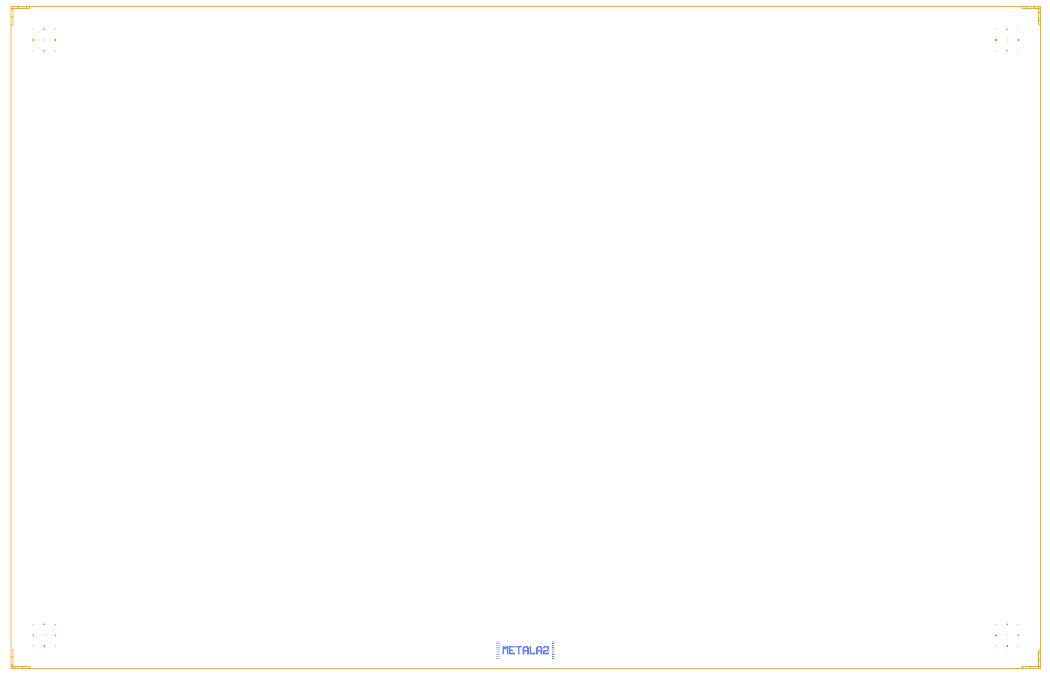

WindowsPath('examples/designs/metal/a2_two_coupled_transmons_step_die.png')

In [4]:
d = Designer("a2_two_coupled_transmons", box=(0, 0, 14000, 9000), chip={"name_chip": "MetalA2"}, live=LIVE)
X0, Y0 = 7000, 4500                              # Metal's 14 × 9 mm chip is centred on (0, 0)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "a2_two_coupled_transmons_step_die.png", size=(1050, 675), width=450)

## 4 · Pads: the PDK pad rule

The tutorial puts its two `LaunchpadWirebond`s at x = ±6 mm on the feedline height, 740 µm in from the die edge.
In the Quantcore PDK the outer edge of every bond pad's etch sits **one dicing-marker width (25 µm) from the die
edge**, whatever the source did: `edge="w"` / `"e"` slides the pad perpendicular to that edge until it is there;
its position along the edge (the feedline height) is kept. The table measures it on the built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

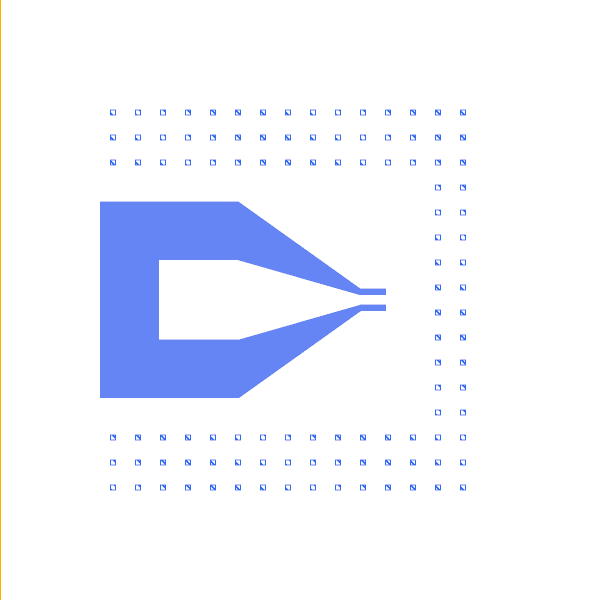

WindowsPath('examples/designs/metal/a2_two_coupled_transmons_step_pads.png')

In [5]:
with d.batch():
    lp1 = d.add("LP1", "metal:LaunchpadWirebond", at=(X0 - 6000, Y0 + 1500), rot=0, edge="w")
    lp2 = d.add("LP2", "metal:LaunchpadWirebond", at=(X0 + 6000, Y0 + 1500), rot=180, edge="e")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "LP1.tie")
snap(d, OUT / "a2_two_coupled_transmons_step_pads.png", box=(0, py - 300, 600, py + 300), size=(600, 600), width=300)

## 5 · Components: two qubits and two tees

**The qubits.** Two `metal:TransmonPocket`s with the tutorial's options: two 425 µm pads in a 650 µm-high pocket,
a `readout` connection pad at the outer top corner and a `coupler` pad at the inner bottom corner (`loc_W` / `loc_H`
pick the corner; Q2 mirrors Q1). Their junctions are the PDK's: `trilayer_junction` makes the Quantcore trilayer
junction explicit and returns its L_J and C_J for the LOM and the FEM junction port (`junction=`). The tutorial gives
no target frequency, so both get the PDK nominal junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with
the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF).

**The tees.** Two `metal:CoupledLineTee`s on the feedline, each with a 350 µm coupled arm; `open_termination=False`
shorts the arm's far end, so each readout routed from `second_end` is a λ/4 shorted at its tee.

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['coupler', 'readout', 'squid_a', 'squid_b'] | clt1 ports: ['prime_end', 'prime_start', 'second_end']


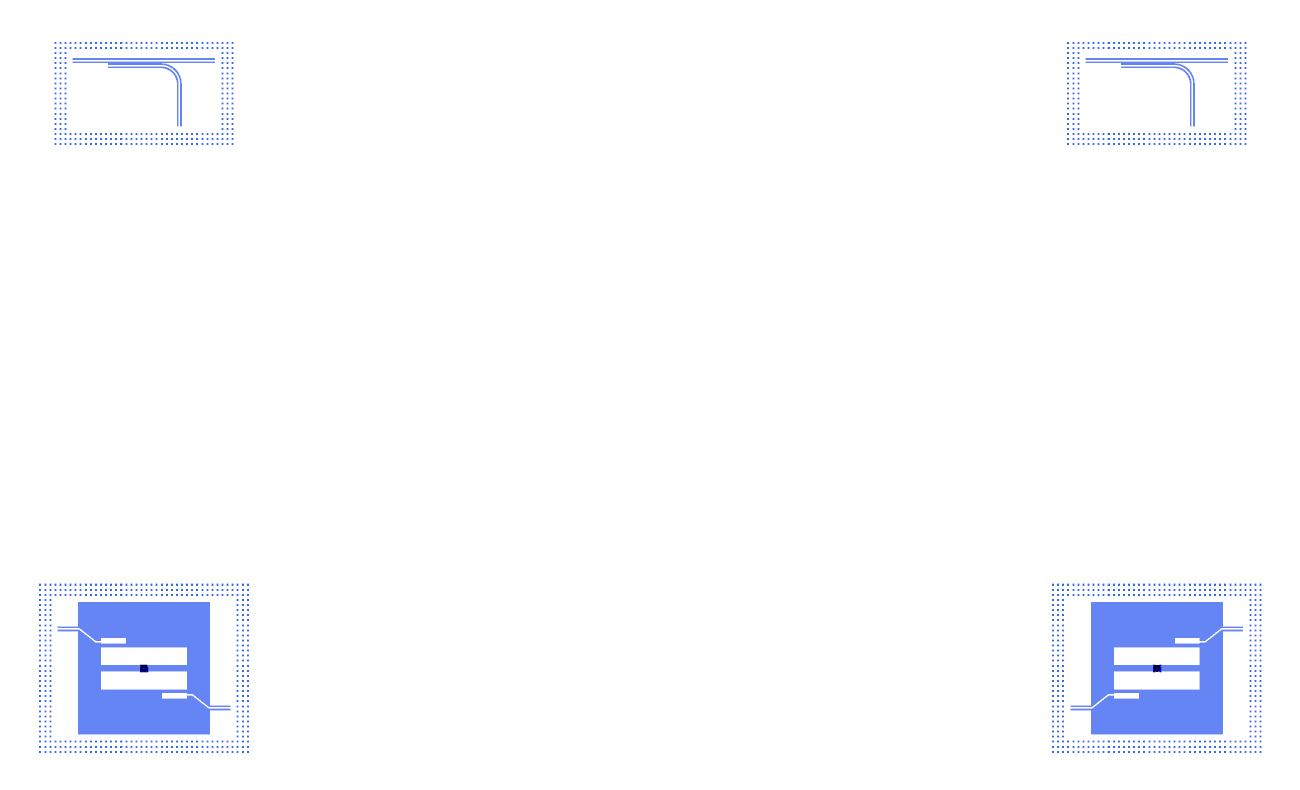

WindowsPath('examples/designs/metal/a2_two_coupled_transmons_step_parts.png')

In [6]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    pocket = dict(pad_width=425, pocket_height=650, junction=JUNCTION, **JJ_PARAMS)
    q1 = d.add("Q1", "metal:TransmonPocket", at=(X0 - 2500, Y0 - 1500),
               connection_pads={"readout": {"loc_W": -1, "loc_H": 1}, "coupler": {"loc_W": 1, "loc_H": -1}}, **pocket)
    q2 = d.add("Q2", "metal:TransmonPocket", at=(X0 + 2500, Y0 - 1500),
               connection_pads={"readout": {"loc_W": 1, "loc_H": 1}, "coupler": {"loc_W": -1, "loc_H": -1}}, **pocket)
    tee = dict(coupling_length=350, down_length=300, fillet=90, open_termination=False)
    clt1 = d.add("clt1", "metal:CoupledLineTee", at=(X0 - 2500, Y0 + 1500), **tee)
    clt2 = d.add("clt2", "metal:CoupledLineTee", at=(X0 + 2500, Y0 + 1500), **tee)
print("Q1 ports:", sorted(q1.ports), "| clt1 ports:", sorted(clt1.ports))
snap(d, OUT / "a2_two_coupled_transmons_step_parts.png", box=(X0 - 3200, Y0 - 2100, X0 + 3200, Y0 + 1800),
     size=(1300, 790), width=480)

## 6 · Routes: feedline, readouts and the bus

- **Feedline:** three `cpw` routes, launchpad → tee → tee → launchpad, on the PDK's default CPW (10 µm centre, 6 µm
  gap) with the tutorial's 90 µm fillet as the turn radius.
- **Readouts:** `meander=7000` / `7200` make fixed-length meanders from each tee's coupled arm to its qubit's
  readout pad; the lengths set the two frequencies (λ/4 on sapphire, ≈ 4 GHz, 200 µm apart for distinct tones).
- **Bus:** an 8 mm meander between the two coupler pads: a λ/2 resonator that couples the qubits.
- **Sim groups:** the pair with its bus (C-matrix), and each qubit with its readout and tee (C-matrix + eigenmode).

route lengths (µm): {'feed_L': 3765.0, 'feed_M': 4300.0, 'feed_R': 3765.0, 'read1': 7000.0, 'read2': 7200.0, 'coupler_bus': 8000.0}


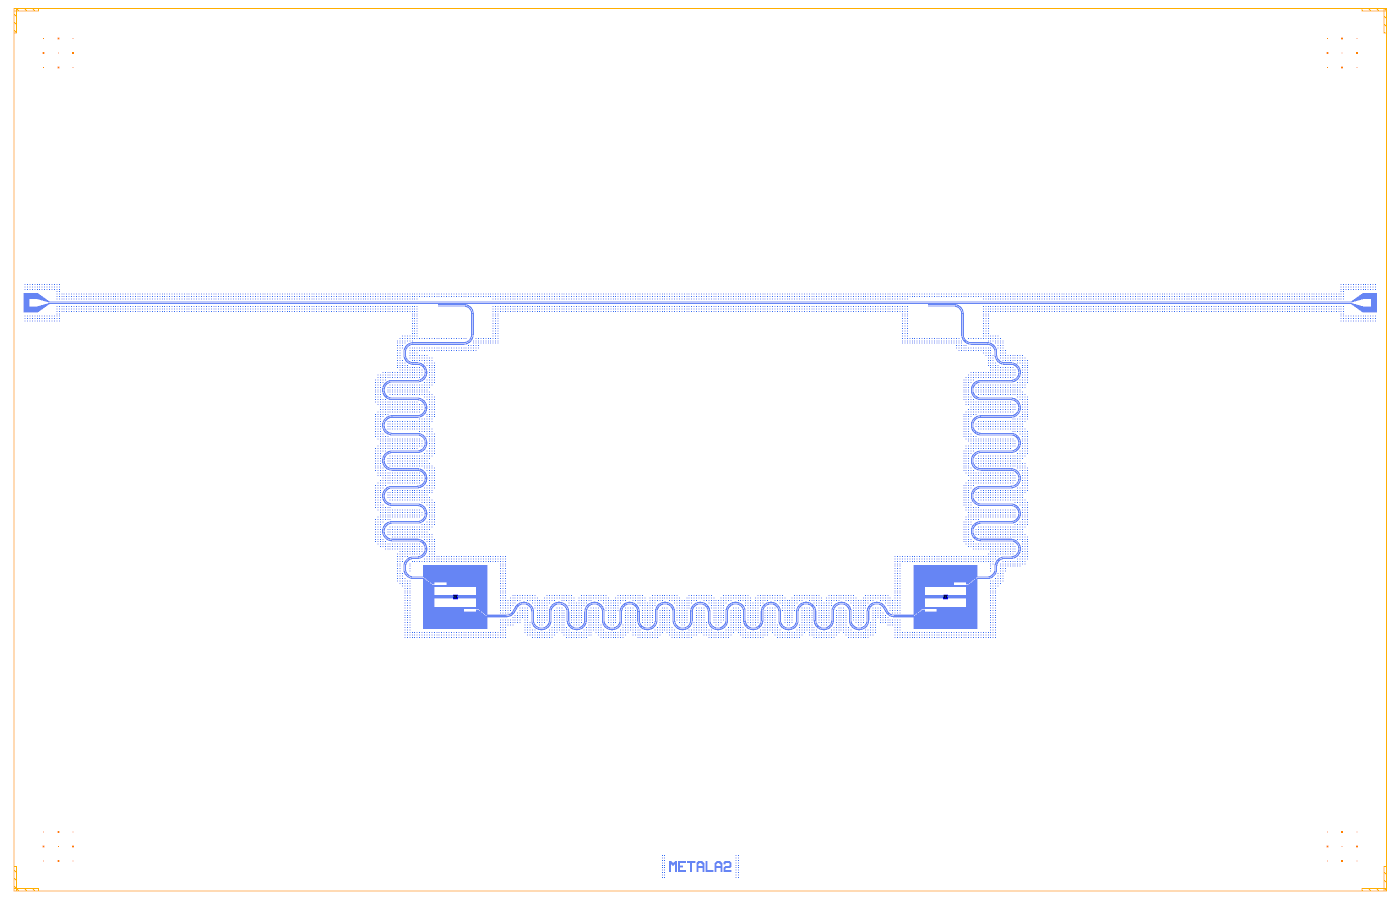

WindowsPath('examples/designs/metal/a2_two_coupled_transmons_step_routes.png')

In [7]:
with d.batch():
    d.route("feed_L", lp1.tie, clt1.prime_start, r=90)
    d.route("feed_M", clt1.prime_end, clt2.prime_start, r=90)
    d.route("feed_R", clt2.prime_end, lp2.tie, r=90)
    d.route("read1", clt1.second_end, q1.readout, meander=7000, r=90)
    d.route("read2", clt2.second_end, q2.readout, meander=7200, r=90)
    d.route("coupler_bus", q1.coupler, q2.coupler, meander=8000, r=90)
d.sim_group("Q1_Q2_bus", ["Q1", "Q2", "coupler_bus"], analyses=["q3d_cmatrix"])
d.sim_group("Q1_read1", ["Q1", "read1", "clt1"], analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("Q2_read2", ["Q2", "read2", "clt2"], analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "a2_two_coupled_transmons_step_routes.png", size=(1400, 900), width=480)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). The pads span the die in x, so only y moves (the source's qubits hang below the
feedline). Then the design is saved: the JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "a2_two_coupled_transmons.json")
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})

content shifted by (0.0, 113.5) µm
<Designer a2_two_coupled_transmons: 6 instances, 6 routes, live=False> → examples\designs\metal\a2_two_coupled_transmons.json
route lengths (µm): {'feed_L': 3765.0, 'feed_M': 4300.0, 'feed_R': 3765.0, 'read1': 7000.0, 'read2': 7200.0, 'coupler_bus': 8000.0}


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, four `dangling_port` warnings (`Q1` / `Q2` `squid_a` / `squid_b`, the junction
attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings** (the pads are at 100 µm, the nominal junctions are in the R_n window, no target is outside 4–8 GHz).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | Q1.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 2 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocket` is two floating pad nodes with the junction
between them plus a node per connection pad; each readout meander from its shorted tee to the readout pad is a λ/4
`TLres`, the tee's coupled section a hanger κ into the feedline (two 50 Ω launchpads); the bus between the two
coupler pads is a λ/2 `TLres`. The port map shows which node each port landed on.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "Q2.", "clt1."))})

**9 nodes · 27 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `clt1.prime` | `LP1.pad`, `LP2.pad`, `clt1.prime`, `clt2.prime` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.readout` | `Q1.readout`, `clt1.second_end` |
| `Q1.coupler` | `Q1.coupler`, `Q2.coupler` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.readout` | `Q2.readout`, `clt2.second_end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_LP1` | R | `clt1.prime` – `gnd` | 50 Ω |
| `Port_LP2` | R | `clt1.prime` – `gnd` | 50 Ω |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 34.3 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 34.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 26.2 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 17 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 1.8 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 34.3 fF |
| `Cg_Q1_coupler` | C | `Q1.island2` – `Q1.coupler` | 17 fF |
| `Cf_Q1_coupler` | C | `Q1.island1` – `Q1.coupler` | 1.8 fF |
| `Cc_Q1_coupler` | C | `Q1.coupler` – `gnd` | 34.3 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 34.3 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 34.3 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 26.2 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_readout` | C | `Q2.island1` – `Q2.readout` | 17 fF |
| `Cf_Q2_readout` | C | `Q2.island2` – `Q2.readout` | 1.8 fF |
| `Cc_Q2_readout` | C | `Q2.readout` – `gnd` | 34.3 fF |
| `Cg_Q2_coupler` | C | `Q2.island2` – `Q1.coupler` | 17 fF |
| `Cf_Q2_coupler` | C | `Q2.island1` – `Q1.coupler` | 1.8 fF |
| `Cc_Q2_coupler` | C | `Q1.coupler` – `gnd` | 34.3 fF |
| `coupler_bus` | TLres | `Q1.coupler` – `gnd` | lambda/2, 8000 µm, 7.877 GHz |
| `clt1` | TLres | `Q1.readout` – `gnd` | lambda/4, 7650 µm, 4.119 GHz |
| `K_clt1` | HANGER | `Q1.readout` – `clt1.prime` | κ 0.108 MHz (L 350 µm) |
| `clt2` | TLres | `Q2.readout` – `gnd` | lambda/4, 7850 µm, 4.014 GHz |
| `K_clt2` | HANGER | `Q2.readout` – `clt1.prime` | κ 0.1 MHz (L 350 µm) |

**Unconnected ports:** none

**Builder notes:**

- clt1: coupled-line κ uses the hanger k for a 3 µm gap (rough)
- clt2: coupled-line κ uses the hanger k for a 3 µm gap (rough)

{'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.readout': 'Q1.readout', 'Q1.coupler': 'Q1.coupler', 'Q2.squid_a': 'Q2.island2', 'Q2.squid_b': 'Q2.island1', 'Q2.readout': 'Q2.readout', 'Q2.coupler': 'Q1.coupler', 'clt1.prime_start': 'clt1.prime', 'clt1.prime_end': 'clt1.prime', 'clt1.second_end': 'Q1.readout'}


## 10 · LOM simulation

Each qubit with its readout, tee and the whole feedline (QuTiP dressed f_q, α, f_r, κ, χ); then the two qubits with
the bus (two qubit modes, the bus mode, static ZZ). With the PDK junction (6.73 nH, 15 fF) the qubits sit near
7.2 GHz, above the ≈ 4 GHz readouts, and onto the 8 mm λ/2 bus (≈ 7.2 GHz loaded): the three modes mix. Both
junctions are identical, so the two qubit modes are degenerate and hybridise (each mode about half on each
junction): a per-pair ZZ is not defined there (the `hybridised` flag). The tutorial states no targets; the
frequency collision is a consequence of the PDK junction, flagged here and not retuned (step 13 shows the knob).

In [11]:
feed = ["LP1", "LP2", "feed_L", "feed_M", "feed_R", "clt1", "clt2"]
results = simulate_groups(d, {"Q1+read1": ["Q1", "read1"] + feed, "Q2+read2": ["Q2", "read2"] + feed})
display(Markdown(groups_md(results)))
bus = simulate_groups(d, {"Q1+Q2+bus": ["Q1", "Q2", "coupler_bus"]}, max_modes=3)
display(Markdown("**Q1 + Q2 + bus, QuCat normal modes:**\n\n" + modes_md(bus["Q1+Q2+bus"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(bus)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+read1 | Q1 | 7.2184 | -321.9 | clt1 | 3.9286 | 0.0896 | -0.292 |
| Q2+read2 | Q2 | 7.2181 | -322 | clt2 | 3.833 | 0.0833 | -0.254 |

**Q1 + Q2 + bus, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| coupler_bus | resonator | 7.1896 | 0 | 6.3 | coupler_bus 0.78, J_Q1 0.11, J_Q2 0.11 |
| Q1 | qubit | 7.5157 | 0 | 145.4 | J_Q2 0.50, J_Q1 0.50 |
| Q2 | qubit | 7.6143 | 0 | 91.5 | J_Q1 0.39, J_Q2 0.39, coupler_bus 0.22 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+Q2+bus | Q1-Q2 | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D **C-matrix** jobs for the coupled pair (`Q1_Q2_bus`: the island, coupler-pad and bus capacitances) and
for each qubit with its readout and tee, and **eigenmode / EPR** jobs for the two readouts (the lines leaving the
box end in 50 Ω, so the mode Q gives κ, and EPR gives the junction participation).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN)
jobs_eig = export_sims(DESIGN, ["Q1_read1", "Q2_read2"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_Q2_bus | `build/jobs/a2_two_coupled_transmons_Q1_Q2_bus_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · waveguide · `Q1.coupler`<br>4 · waveguide · `Q2.coupler`<br>5 · edge · `read1`<br>6 · edge · `read2` | `Q1.island2`, `Q2.island2`, `Q1.coupler`, `Q2.coupler`, `read1`, `read2`, `Q1.island1`, `Q2.island1` |
| Q1_read1 | `build/jobs/a2_two_coupled_transmons_Q1_read1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `clt1.second_end`<br>3 · waveguide · `Q1.readout`<br>4 · edge · `coupler_bus`<br>5 · edge · `feed_L`<br>6 · edge · `feed_M` | `Q1.island2`, `Q1.readout`, `coupler_bus`, `feed_L`, `Q1.island1` |
| Q2_read2 | `build/jobs/a2_two_coupled_transmons_Q2_read2_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `clt2.second_end`<br>3 · waveguide · `Q2.readout`<br>4 · edge · `coupler_bus`<br>5 · edge · `feed_M`<br>6 · edge · `feed_R` | `Q2.island2`, `Q2.readout`, `coupler_bus`, `feed_M`, `Q2.island1` |
| Q1_read1 | `build/jobs/a2_two_coupled_transmons_Q1_read1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `coupler_bus`<br>3 · edge_lumped · `feed_L`<br>4 · edge_lumped · `feed_M` | `Q1.island2`, `coupler_bus`, `feed_L`, `feed_M`, `Q1.island1` |
| Q2_read2 | `build/jobs/a2_two_coupled_transmons_Q2_read2_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `coupler_bus`<br>3 · edge_lumped · `feed_M`<br>4 · edge_lumped · `feed_R` | `Q2.island2`, `coupler_bus`, `feed_M`, `feed_R`, `Q2.island1` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q1_Q2_bus', 'Q1_read1', 'Q2_read2'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q1_Q2_bus · q3d, Q1_read1 · q3d, Q2_read2 · q3d, Q1_read1 · eigenmode, Q2_read2 · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here the bus, 8000 → 6500 µm — rebuild, re-run the LOM of the coupled pair and compare.
With the PDK junctions the qubits moved up to ≈ 7.2 GHz, right onto the 8 mm bus (step 10: the bus mode carries both
junctions). The shorter bus (λ/2 ≈ 8.8 GHz) leaves the qubit band: the bus mode is the bus alone again, and the two
qubit modes are the clean symmetric / antisymmetric pair of the identical junctions, split by 2g through the bus
(still degenerate qubits, so ZZ stays undefined; detuning one junction, e.g. `trilayer_junction(..., lj_nH=7.5)`,
would separate them).

In [15]:
d2 = design_copy(DESIGN)
d2["coupler_bus"].set(length=6500)               # bus 8000 → 6500 µm
bus2 = simulate_groups(d2, {"Q1+Q2+bus": ["Q1", "Q2", "coupler_bus"]}, max_modes=3)
display(Markdown(params_delta_md(bus, bus2)))
display(Markdown("**After, QuCat normal modes:**\n\n" + modes_md(bus2["Q1+Q2+bus"])))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+Q2+bus: coupler_bus.f_GHz` | 7.0755 | 8.8421 | +1.767 |
| `Q1+Q2+bus: coupler_bus.kappa_MHz` | 0 | 0 | +0 |
| `Q1+Q2+bus: coupler_bus.chi_MHz` | -242.32 | -5.2008 | +237.1 |
| `Q1+Q2+bus: Q1.f_q_GHz` | 7.212 | 7.1929 | -0.01918 |
| `Q1+Q2+bus: Q1.alpha_MHz` | -152.38 | -298.77 | -146.4 |
| `Q1+Q2+bus: Q2.f_q_GHz` | 7.4245 | 7.212 | -0.2125 |
| `Q1+Q2+bus: Q2.alpha_MHz` | -16.652 | -18.363 | -1.711 |

**After, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 7.4896 | 0 | 137.5 | J_Q1 0.49, J_Q2 0.49, coupler_bus 0.02 |
| Q2 | qubit | 7.5157 | 0 | 145.4 | J_Q1 0.50, J_Q2 0.50 |
| coupler_bus | resonator | 8.8493 | 0 | 0.1 | coupler_bus 0.98, J_Q1 0.01, J_Q2 0.01 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The A.2 tutorial never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\a2_two_coupled_transmons.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 8081 |
| 2/0 | JJ_STRAIGHT | 2 |
| 3/0 | M3 | 8074 |
| 4/0 | JJ_BENT | 2 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 8072 holes on the mask.

→ `build/a2_two_coupled_transmons_fab.oas`

## 15 · Snapshots

The full chip; Q1 with its two connection pads; its trilayer junction; the clt1 coupled-line tee; the **fab mask**
round Q1 (1/0 etch with the PDK cheese band, the 3/0 keep-out, the junction layers); and the die frame's
south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are read from the design (after the
centring shift).

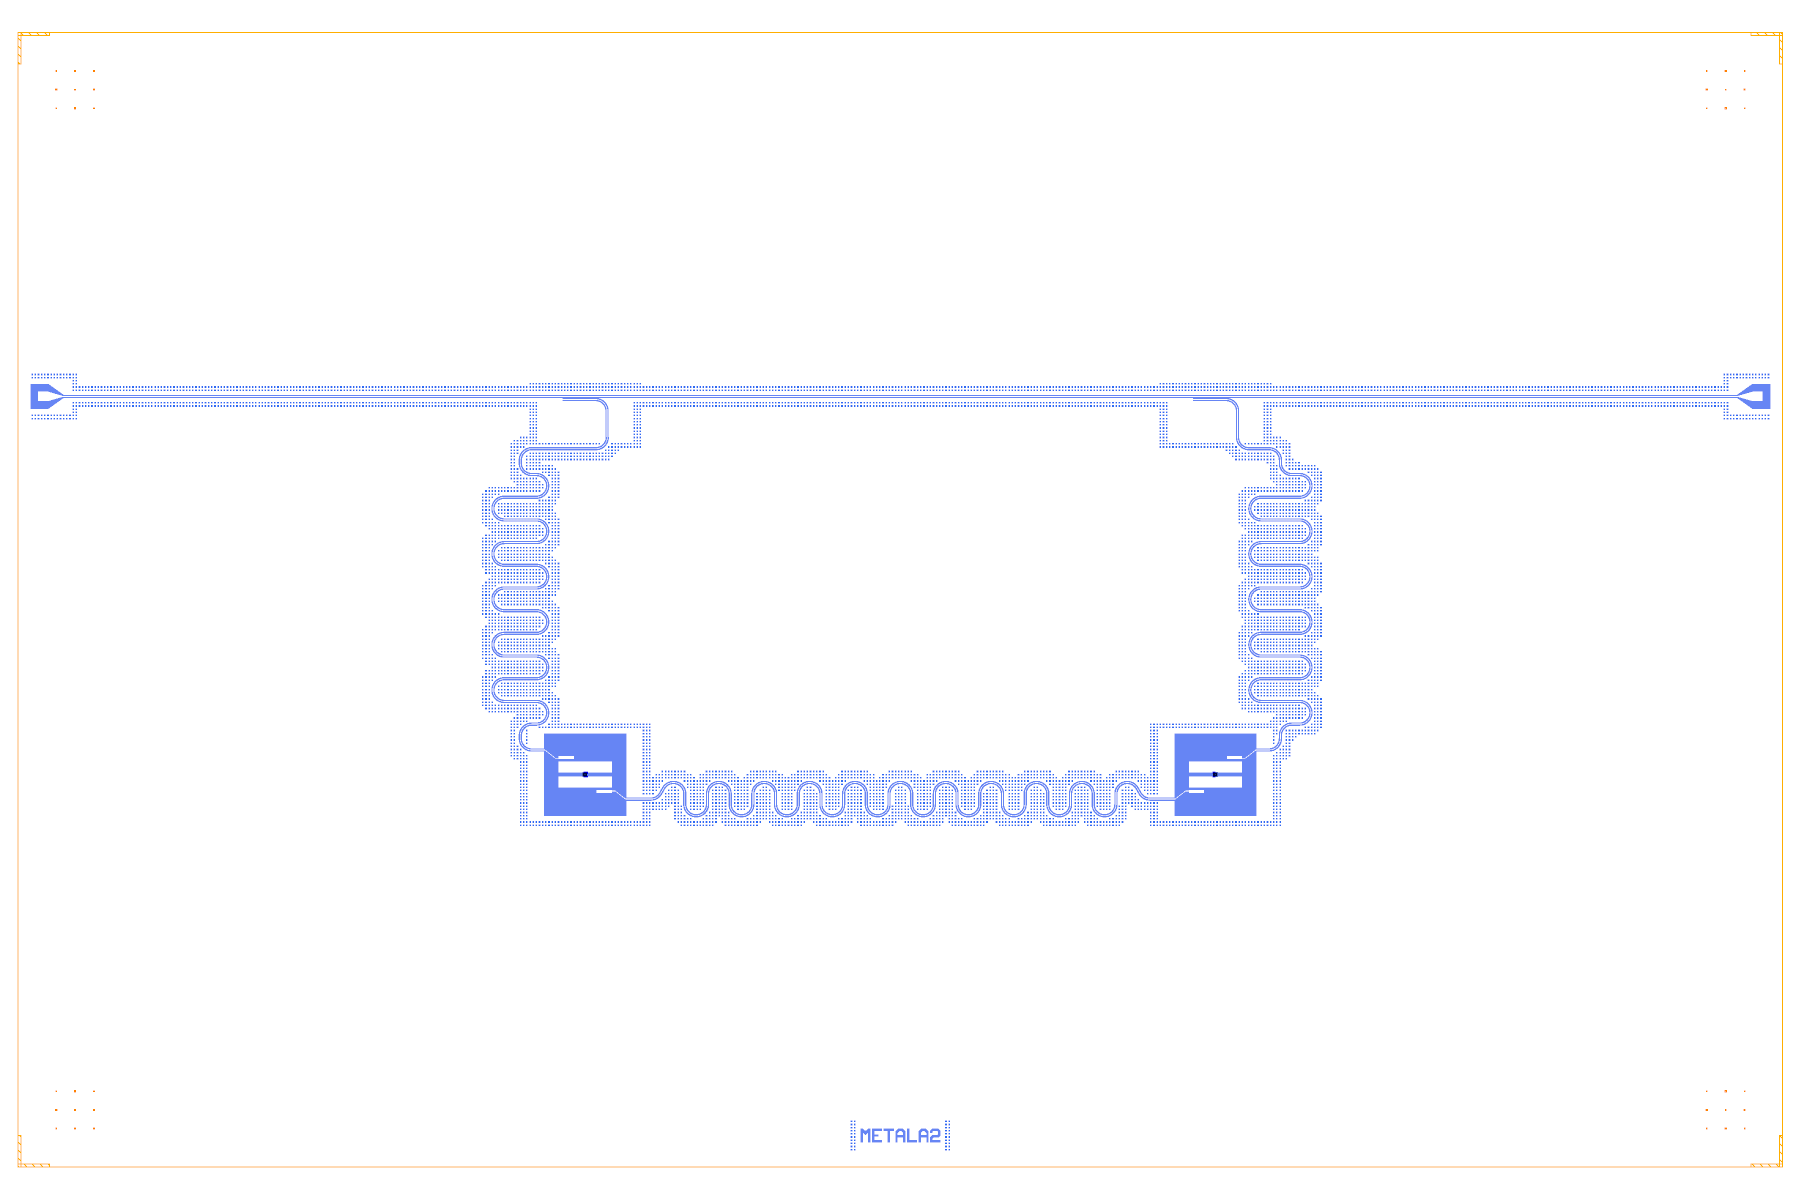

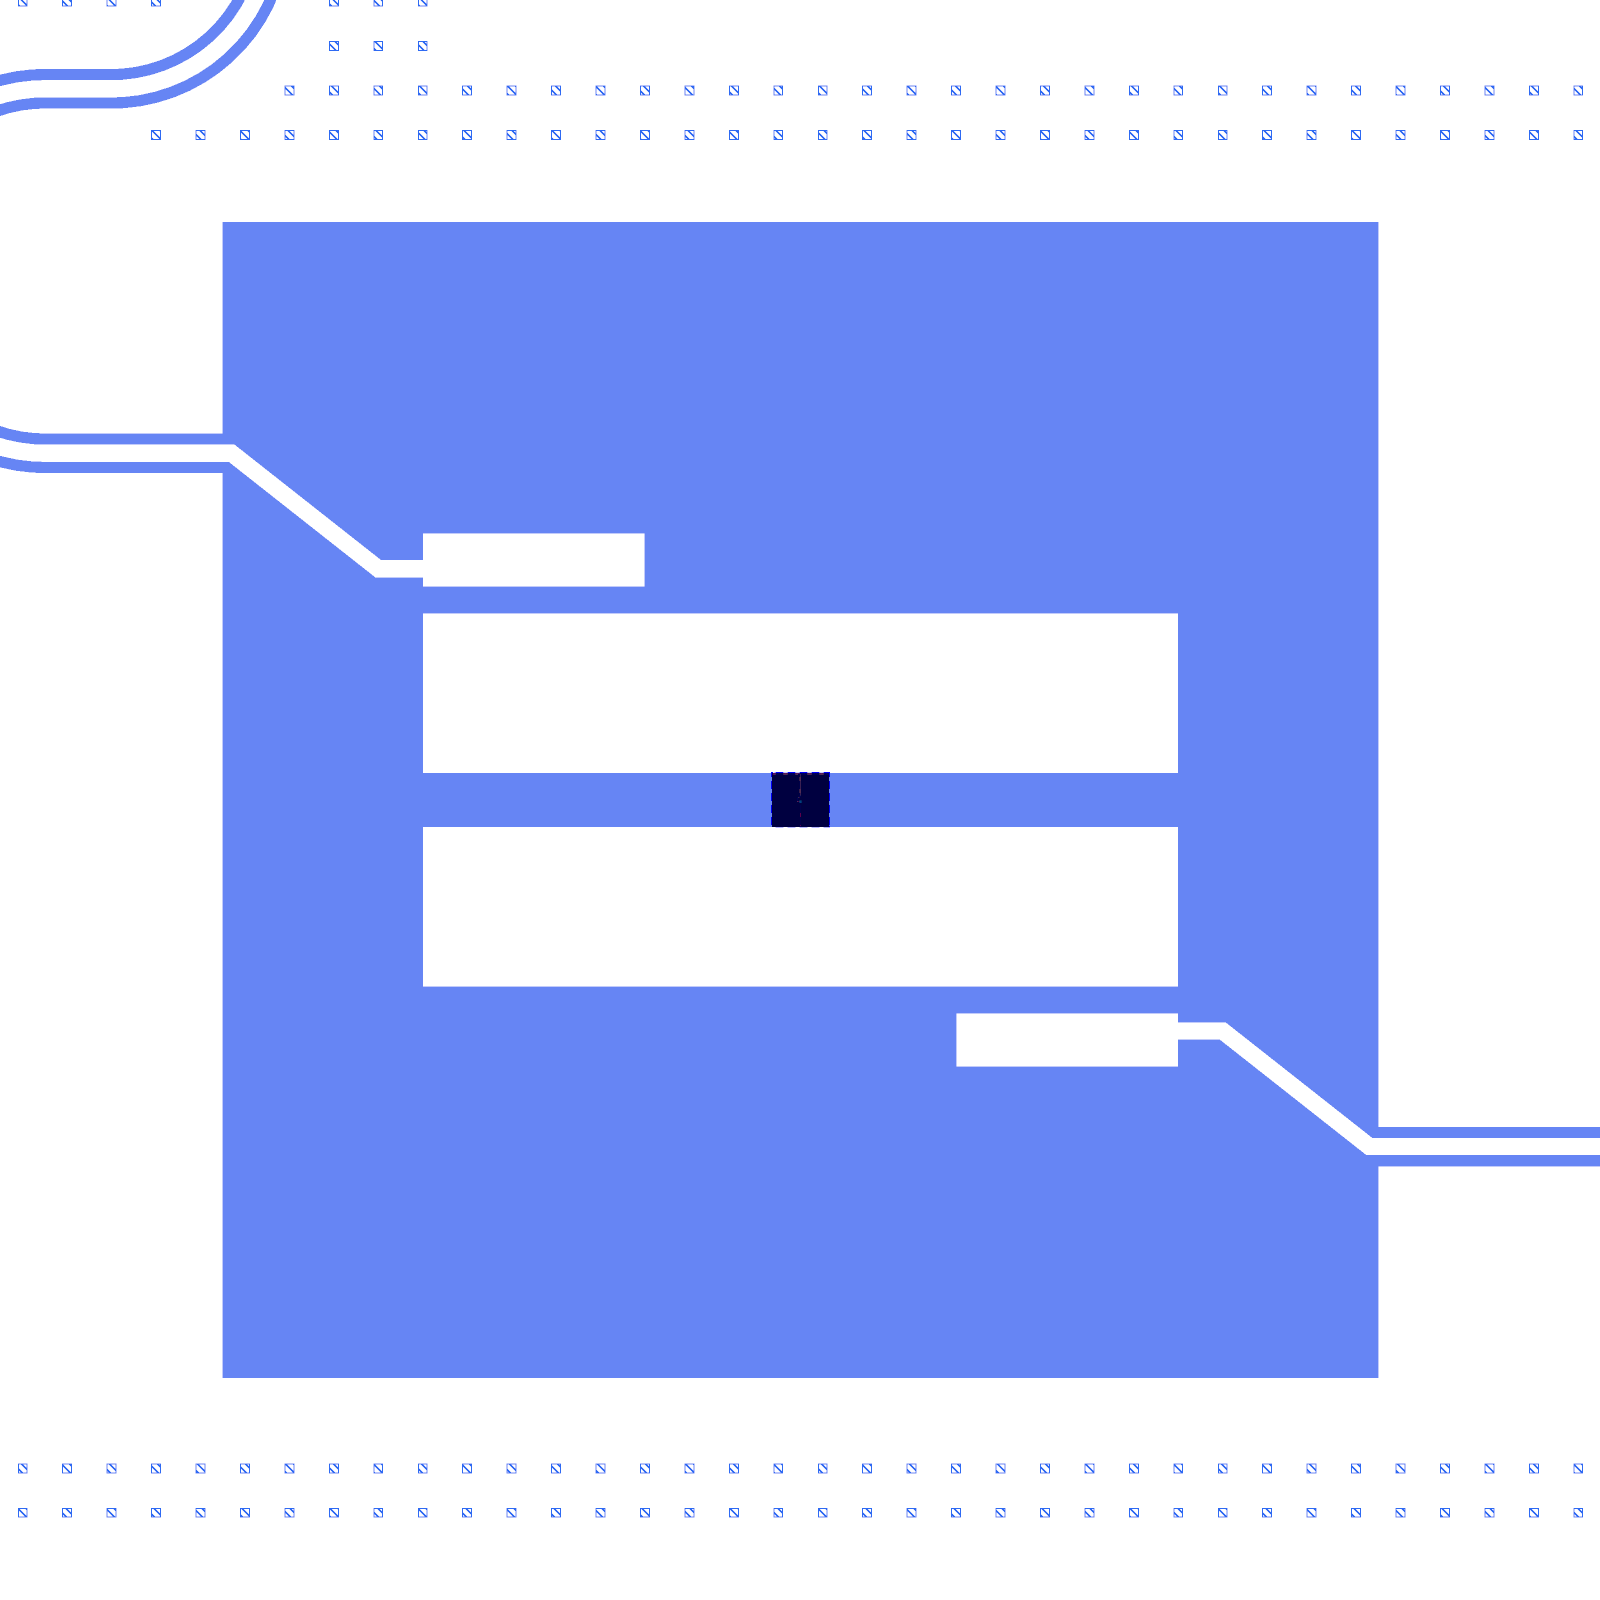

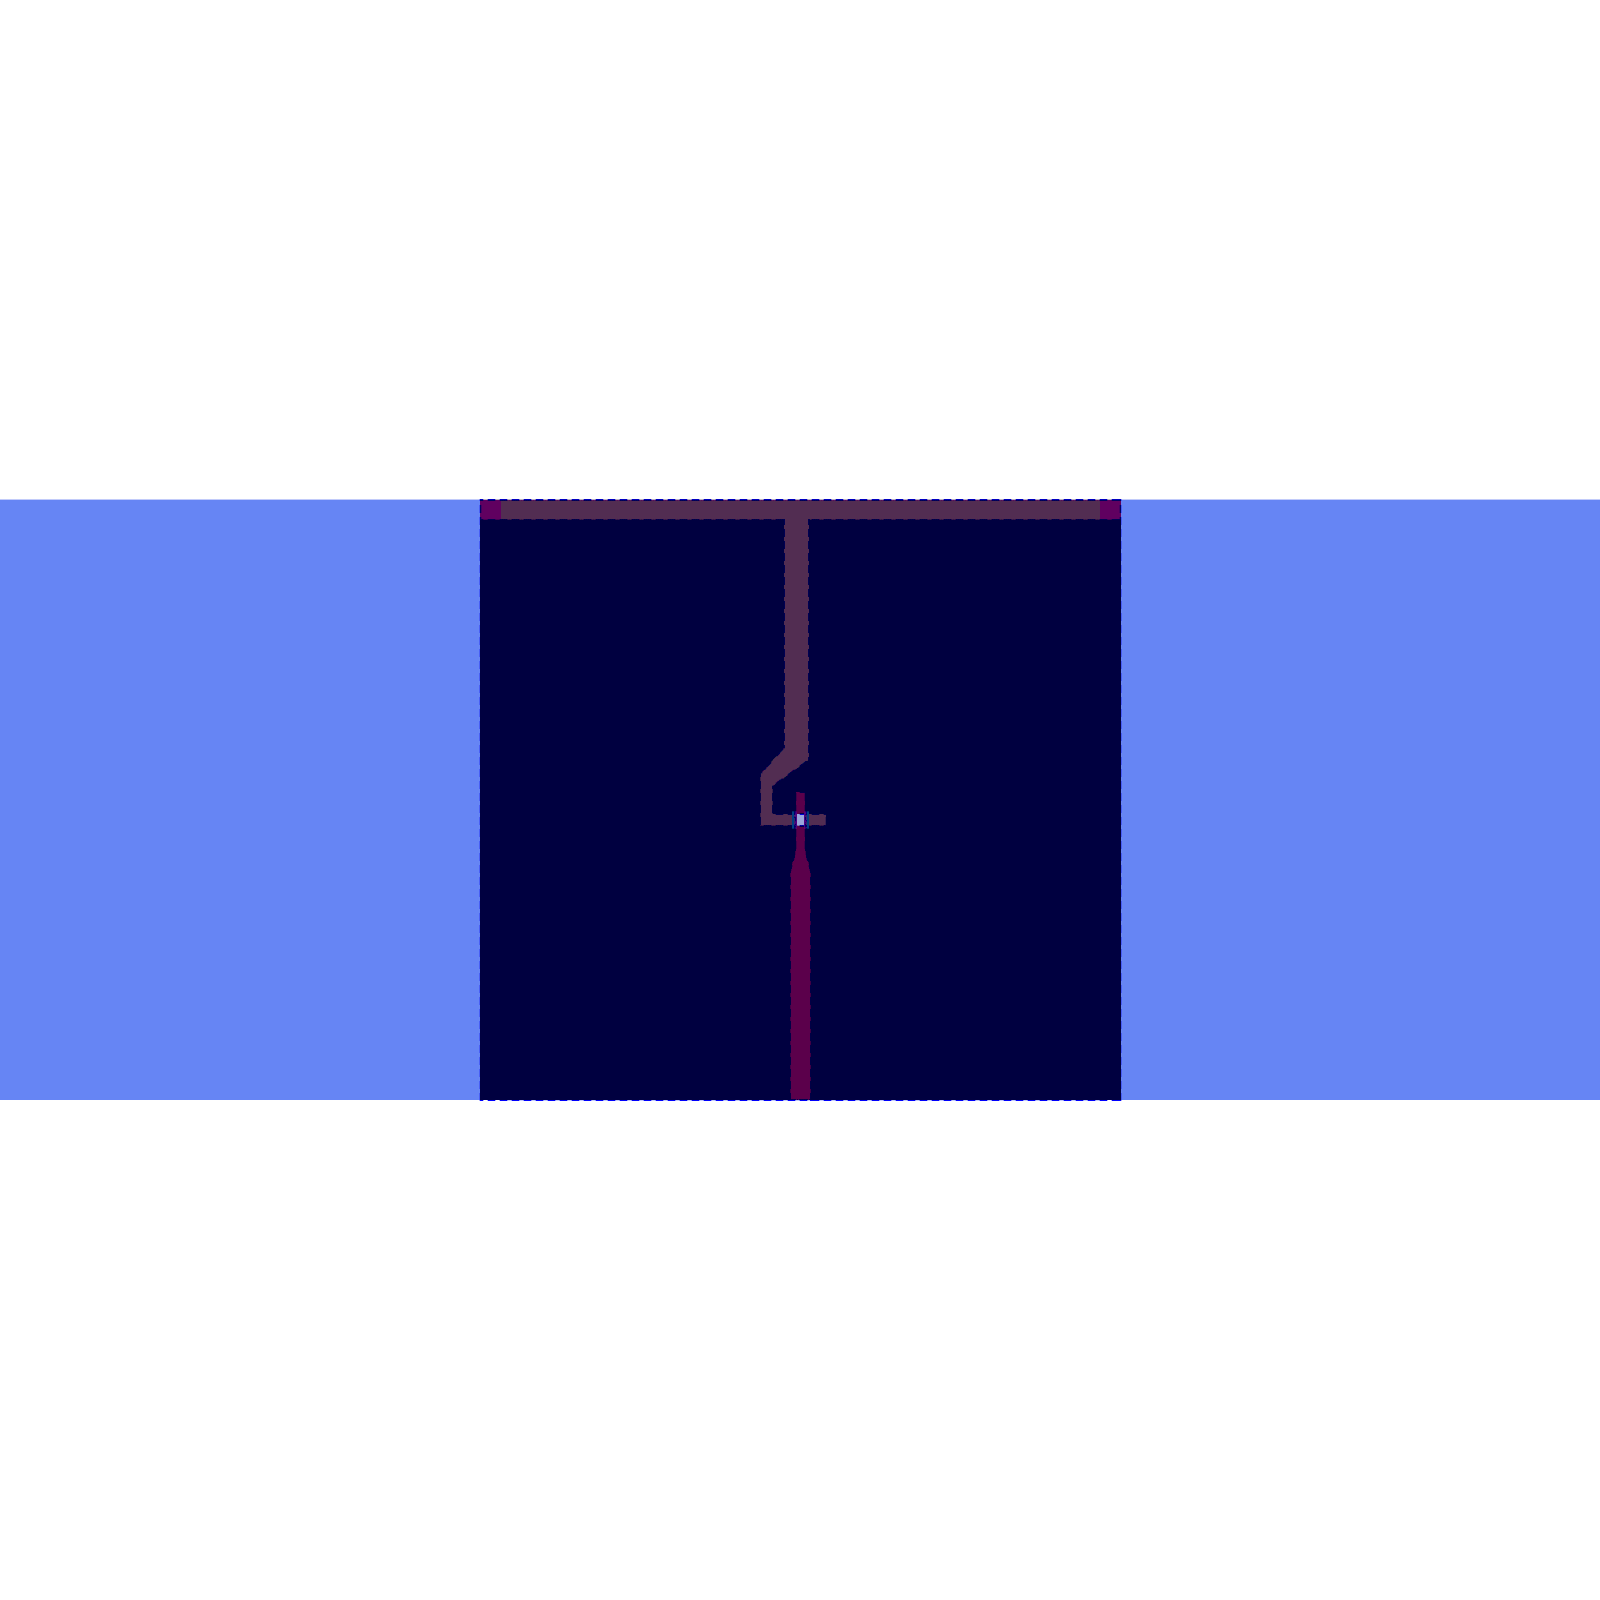

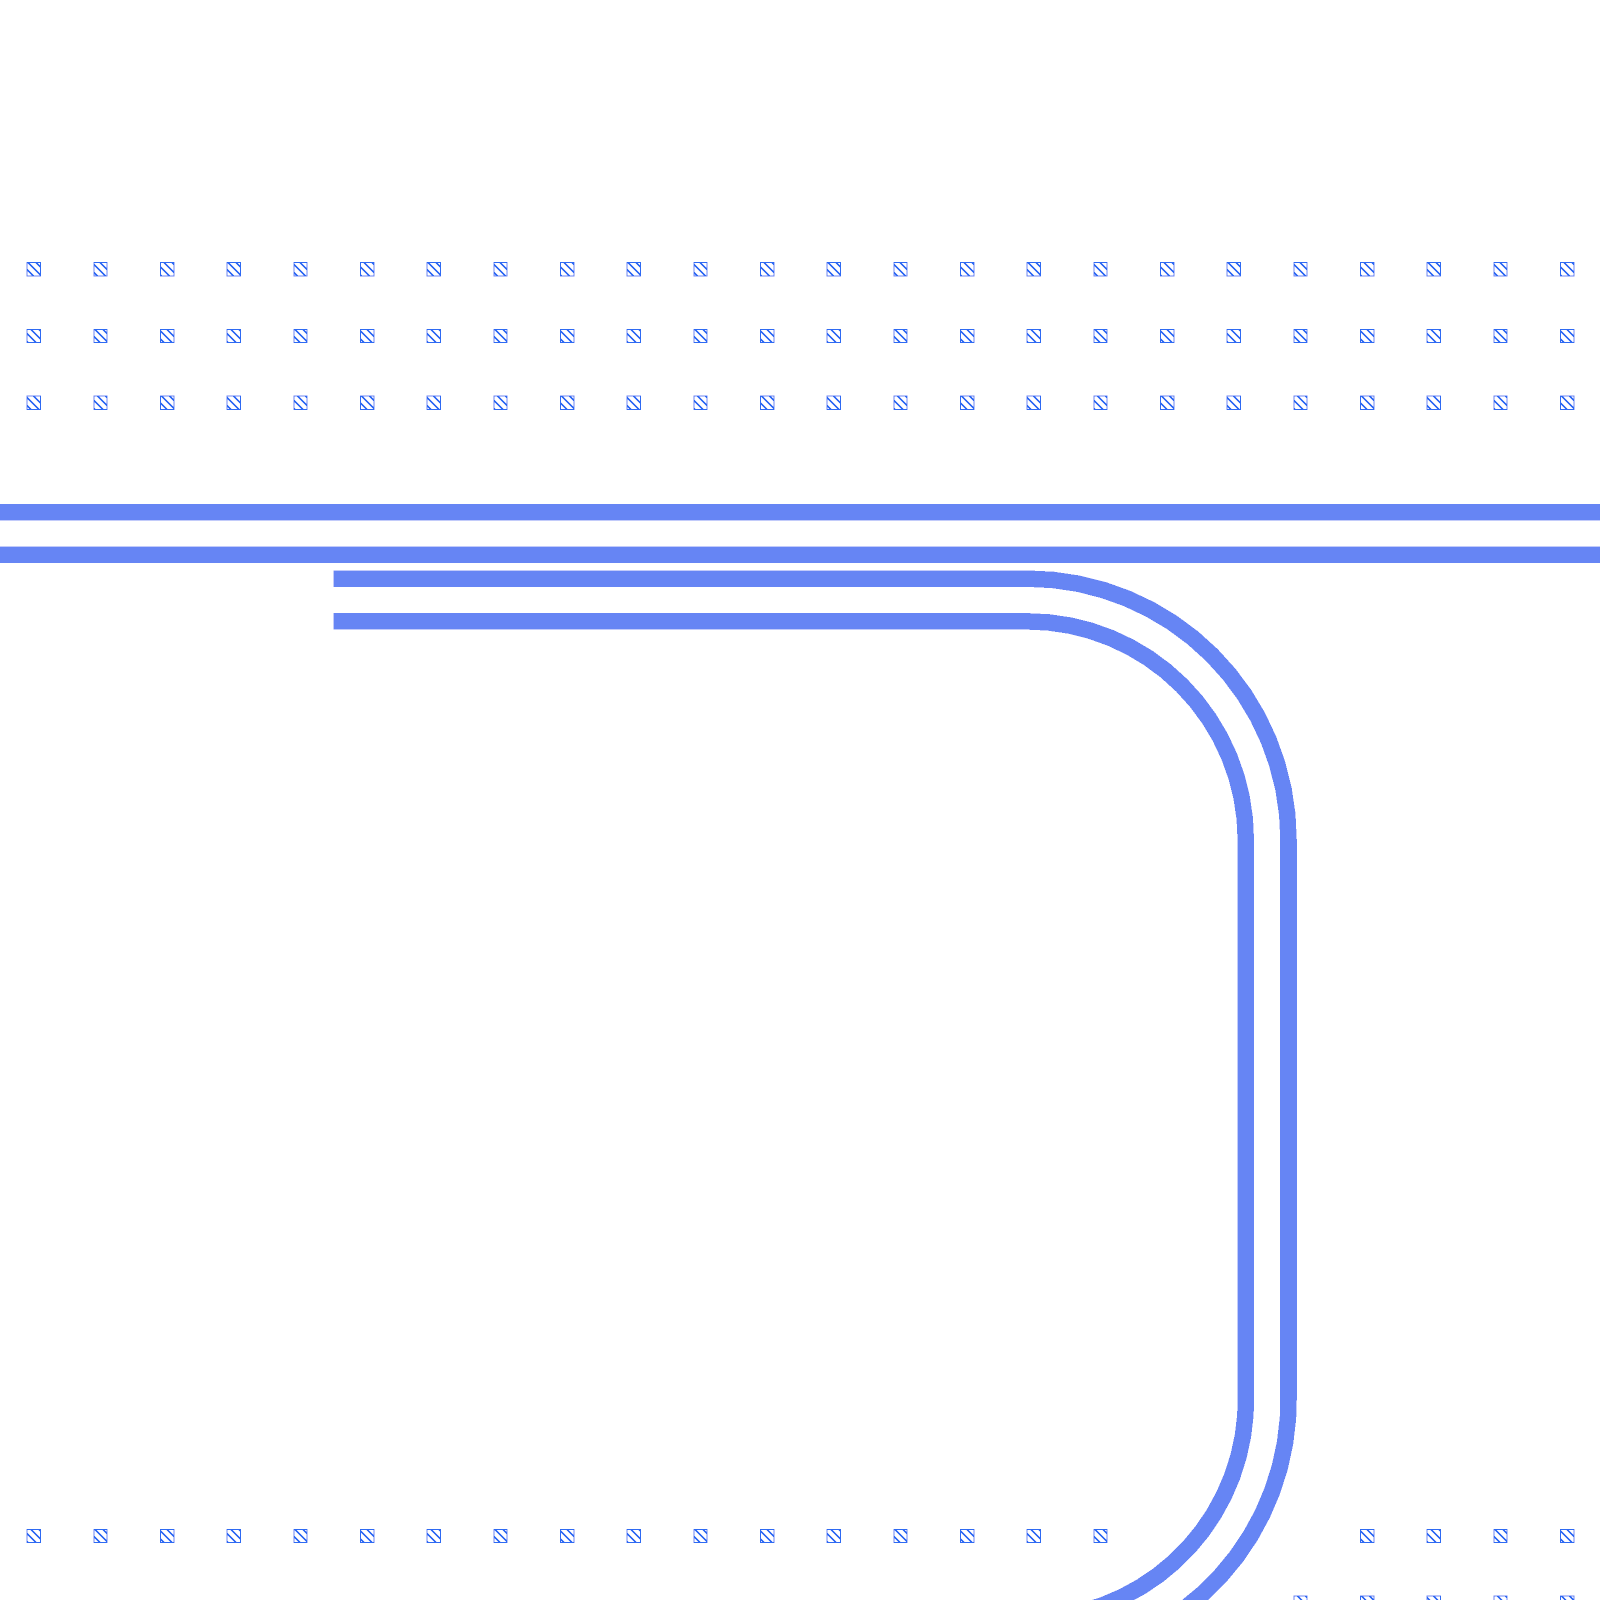

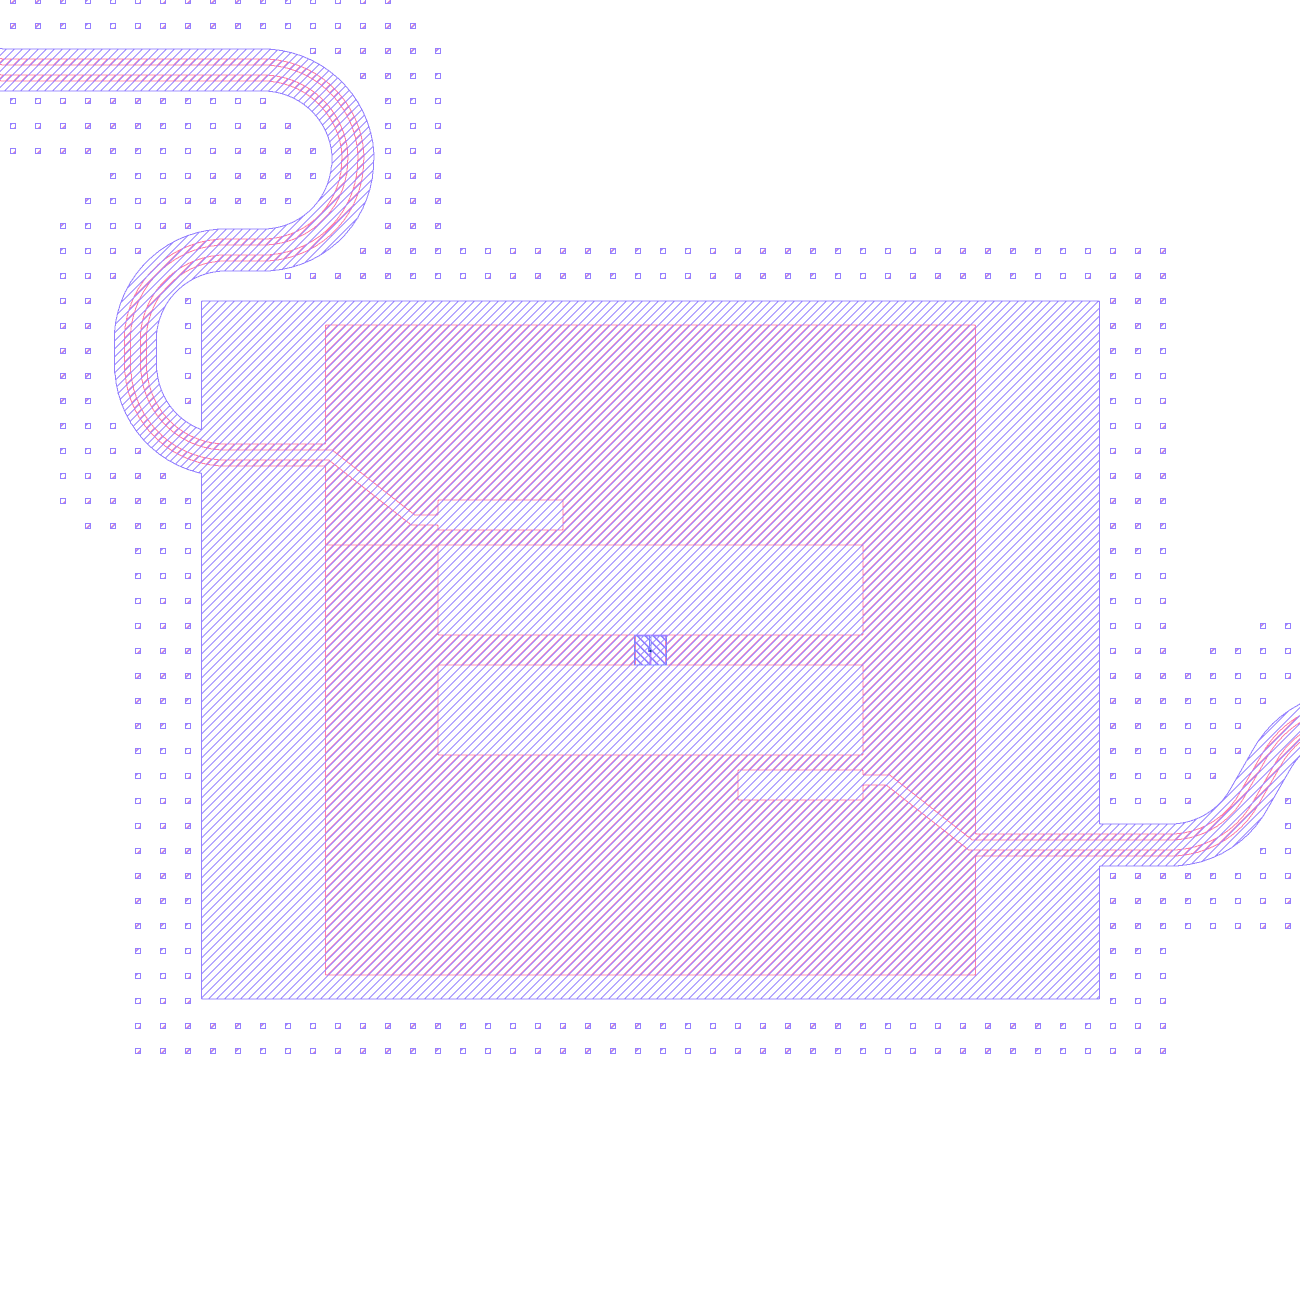

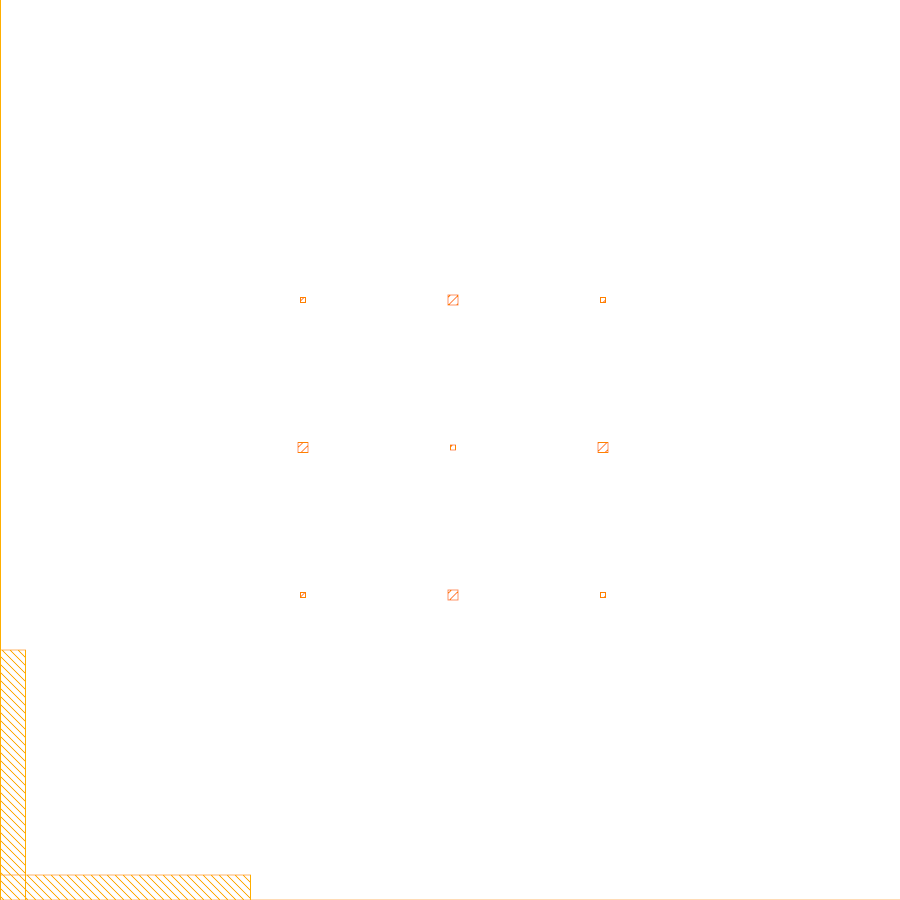

In [17]:
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
TX, TY = d.data["instances"]["clt1"]["place"]["at"]
show_snapshot(d, OUT / "a2_two_coupled_transmons.png", size=(1800, 1200))
show_snapshot(d, OUT / "a2_two_coupled_transmons_q1.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a2_two_coupled_transmons_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "a2_two_coupled_transmons_tee.png", box=(TX - 300, TY - 400, TX + 300, TY + 200), width=360)
snap_file(Path("build") / "a2_two_coupled_transmons_fab.oas", OUT / "a2_two_coupled_transmons_cheese.png",
          box=(QX - 650, QY - 650, QX + 650, QY + 650), size=(1300, 1300), width=420)
show_snapshot(d, OUT / "a2_two_coupled_transmons_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins, the readout (7.0 / 7.2 mm) and bus (8.0 mm) lengths, the sim groups |
| PDK changes | QCT frame on the source's 14 × 9 mm box; sapphire stack; launchpads 100 µm from the west / east edges (were 740 µm); trilayer junctions (PDK nominal); PDK cheese band; content centred (shift (0, +114) µm) |
| differs | the meanders' shapes (qcc router); f_q ≈ 7.2 GHz with the PDK junction (the 10 nH Metal default gave 6.50 GHz); the identical qubits hybridise, as in the tutorial, and now sit on the 8 mm bus (≈ 7.2 GHz); a 6.5 mm bus would clear them (step 13) |
| PDK design warnings | none |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |